# 01 · Text Preprocessing (Module I)

**Theory.** Raw text is a string of characters; models need a sequence of units (tokens).
*Tokenization* splits text into tokens. *Normalisation* makes different surface forms count as one
feature: lowercasing, removing punctuation and very common *stop words*, and reducing words to a
base form. *Stemming* chops suffixes with rules ("studies" → "studi"); *lemmatization* looks the word
up in a dictionary using its part of speech ("studies"/VERB → "study"). Every step shrinks the
vocabulary, but each one can also throw away meaning, so the choice depends on the task.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # lets us "import src..." from notebooks/

import time
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, SnowballStemmer, WordNetLemmatizer

from src.utils import FAST
from src.data import load
from src import preprocess as pp
from src.evaluate import save_results

pd.set_option("display.max_colwidth", 140)
nlp = spacy.load("en_core_web_sm")
print("FAST mode:", FAST)

FAST mode: False


## 5 sample AG News headlines + descriptions
One per class, plus one extra with numbers and an abbreviation.

In [2]:
ag = load("ag_train")
samples = pd.concat([ag.groupby("label").head(1), ag[ag.text.str.contains(r"\$\d")].head(1)])
samples = samples[["label_name", "text"]].reset_index(drop=True)
samples

,label_name,text
0,World,Powell: Worsening insurgency makes election difficult in Iraq US Secretary of State Colin Powell said Sunday that the escalating insurge...
1,Business,"GE ready to sell India BPO ops WASHINGTON: General Electric Co (GE), which began business process outsourcing to India long before the t..."
2,Sci/Tech,"Salesforce.com Touts Customer-Service Apps Seeking to diversify beyond its sales-force-automation roots, Salesforce.com on Wednesday int..."
3,Sports,"Soccer: Rooney guns down Turks with hattrick on Man United debut MANCHESTER, England : Wayne Rooney opened his Manchester United career ..."
4,Business,"Nestle's 1st-Half Net Profit Hits $2.28B VEVEY, Switzerland Aug. 18, 2004 Nestle SA posted a modest 2 percent increase in profits for th..."


## Step 1 · Lowercasing
"Stocks" and "stocks" become one feature. Cost: we lose the cue that "Apple" (company) differs from "apple".

In [3]:
pd.DataFrame({"before": samples.text, "after": samples.text.map(pp.lowercase)})

,before,after
0,Powell: Worsening insurgency makes election difficult in Iraq US Secretary of State Colin Powell said Sunday that the escalating insurge...,powell: worsening insurgency makes election difficult in iraq us secretary of state colin powell said sunday that the escalating insurge...
1,"GE ready to sell India BPO ops WASHINGTON: General Electric Co (GE), which began business process outsourcing to India long before the t...","ge ready to sell india bpo ops washington: general electric co (ge), which began business process outsourcing to india long before the t..."
2,"Salesforce.com Touts Customer-Service Apps Seeking to diversify beyond its sales-force-automation roots, Salesforce.com on Wednesday int...","salesforce.com touts customer-service apps seeking to diversify beyond its sales-force-automation roots, salesforce.com on wednesday int..."
3,"Soccer: Rooney guns down Turks with hattrick on Man United debut MANCHESTER, England : Wayne Rooney opened his Manchester United career ...","soccer: rooney guns down turks with hattrick on man united debut manchester, england : wayne rooney opened his manchester united career ..."
4,"Nestle's 1st-Half Net Profit Hits $2.28B VEVEY, Switzerland Aug. 18, 2004 Nestle SA posted a modest 2 percent increase in profits for th...","nestle's 1st-half net profit hits $2.28b vevey, switzerland aug. 18, 2004 nestle sa posted a modest 2 percent increase in profits for th..."


## Step 2 · Tokenization: NLTK vs regex vs spaCy
The three tokenizers disagree on contractions, currency, abbreviations and hyphens.

In [4]:
tricky = "The U.S. firm AT&T didn't pay $10.5m to e-mail users in N.Y. -- shares fell 3%."
tok = {
    "NLTK word_tokenize": pp.tokenize(tricky),
    "regex [A-Za-z0-9]+": pp.regex_tokenize(tricky),
    "spaCy": [t.text for t in nlp(tricky)],
}
for name, toks in tok.items():
    print(f"{name:20s} ({len(toks):2d}) {toks}")

NLTK word_tokenize   (22) ['The', 'U.S.', 'firm', 'AT', '&', 'T', 'did', "n't", 'pay', '$', '10.5m', 'to', 'e-mail', 'users', 'in', 'N.Y.', '--', 'shares', 'fell', '3', '%', '.']
regex [A-Za-z0-9]+   (20) ['The', 'U', 'S', 'firm', 'AT', 'T', "didn't", 'pay', '10', '5m', 'to', 'e', 'mail', 'users', 'in', 'N', 'Y', 'shares', 'fell', '3']
spaCy                (23) ['The', 'U.S.', 'firm', 'AT&T', 'did', "n't", 'pay', '$', '10.5', 'm', 'to', 'e', '-', 'mail', 'users', 'in', 'N.Y.', '--', 'shares', 'fell', '3', '%', '.']


- NLTK splits *didn't* → *did* + *n't* (Penn Treebank convention) and keeps *U.S.* whole.
- The regex drops every symbol, so *$*, *%* and *&* vanish and *AT&T* becomes *AT*, *T*.
- spaCy splits *e-mail* into *e*, *-*, *mail* and *$10.5m* into *$*, *10.5*, *m*.

On the 5 samples (token counts per tokenizer):

In [5]:
pd.DataFrame({
    "nltk": samples.text.map(lambda t: len(pp.tokenize(t))),
    "regex": samples.text.map(lambda t: len(pp.regex_tokenize(t))),
    "spacy": samples.text.map(lambda t: len(nlp(t))),
    "first 12 NLTK tokens": samples.text.map(lambda t: pp.tokenize(t.lower())[:12]),
})

,nltk,regex,spacy,first 12 NLTK tokens
0,46,43,46,"[powell, :, worsening, insurgency, makes, election, difficult, in, iraq, us, secretary, of]"
1,45,39,45,"[ge, ready, to, sell, india, bpo, ops, washington, :, general, electric, co]"
2,29,33,37,"[salesforce.com, touts, customer-service, apps, seeking, to, diversify, beyond, its, sales-force-automation, roots, ,]"
3,47,43,49,"[soccer, :, rooney, guns, down, turks, with, hattrick, on, man, united, debut]"
4,56,52,58,"[nestle, 's, 1st-half, net, profit, hits, $, 2.28b, vevey, ,, switzerland, aug.]"


## Step 3 · Stop-word removal
NLTK's English list has 198 words. What gets removed from each sample:

In [6]:
nltk_stop = set(stopwords.words("english"))
print("NLTK stop words:", len(nltk_stop), "| ours (negations kept):", len(pp.STOP_WORDS))
rows = []
for text in samples.text:
    toks = pp.tokenize(text.lower())
    rows.append({"removed": [t for t in toks if t in pp.STOP_WORDS],
                 "kept": pp.remove_stopwords(toks)})
pd.DataFrame(rows)

NLTK stop words: 198 | ours (negations kept): 196


,removed,kept
0,"[in, of, that, the, in, the, of, in, the, while, were, in, in]","[powell, :, worsening, insurgency, makes, election, difficult, iraq, us, secretary, state, colin, powell, said, sunday, escalating, insu..."
1,"[to, which, to, before, the, and, the, a, is, to, its]","[ge, ready, sell, india, bpo, ops, washington, :, general, electric, co, (, ge, ), ,, began, business, process, outsourcing, india, long..."
2,"[to, its, on, a, and]","[salesforce.com, touts, customer-service, apps, seeking, diversify, beyond, sales-force-automation, roots, ,, salesforce.com, wednesday,..."
3,"[down, with, on, his, in, a, as, his, in, a, d]","[soccer, :, rooney, guns, turks, hattrick, man, united, debut, manchester, ,, england, :, wayne, rooney, opened, manchester, united, car..."
4,"['s, a, in, for, the, of, the, as, it, such, as, for, and, as, as, which]","[nestle, 1st-half, net, profit, hits, $, 2.28b, vevey, ,, switzerland, aug., 18, ,, 2004, nestle, sa, posted, modest, 2, percent, increa..."


**Where stop-word removal hurts.** The full NLTK list contains *not*, *no*, *nor* and *don't*, so
naive removal flips the meaning of a sentence. That is why `src/preprocess.py` keeps negations.

In [7]:
for s in ["The movie was not good.", "No deal was reached.", "This is not a bad phone."]:
    toks = pp.tokenize(s.lower())
    print(f"{s:28s} naive: {pp.remove_stopwords(toks, nltk_stop)!s:28s} ours: {pp.remove_stopwords(toks)}")

The movie was not good.      naive: ['movie', 'good', '.']       ours: ['movie', 'not', 'good', '.']
No deal was reached.         naive: ['deal', 'reached', '.']     ours: ['no', 'deal', 'reached', '.']
This is not a bad phone.     naive: ['bad', 'phone', '.']        ours: ['not', 'bad', 'phone', '.']


## Step 4 · Punctuation removal
Drop tokens made only of punctuation. Words containing punctuation (*n't*, *u.s.*) survive.

In [8]:
pd.DataFrame([{"before": pp.tokenize(t.lower()), "after": pp.remove_punctuation(pp.tokenize(t.lower()))}
              for t in samples.text])

,before,after
0,"[powell, :, worsening, insurgency, makes, election, difficult, in, iraq, us, secretary, of, state, colin, powell, said, sunday, that, th...","[powell, worsening, insurgency, makes, election, difficult, in, iraq, us, secretary, of, state, colin, powell, said, sunday, that, the, ..."
1,"[ge, ready, to, sell, india, bpo, ops, washington, :, general, electric, co, (, ge, ), ,, which, began, business, process, outsourcing, ...","[ge, ready, to, sell, india, bpo, ops, washington, general, electric, co, ge, which, began, business, process, outsourcing, to, india, l..."
2,"[salesforce.com, touts, customer-service, apps, seeking, to, diversify, beyond, its, sales-force-automation, roots, ,, salesforce.com, o...","[salesforce.com, touts, customer-service, apps, seeking, to, diversify, beyond, its, sales-force-automation, roots, salesforce.com, on, ..."
3,"[soccer, :, rooney, guns, down, turks, with, hattrick, on, man, united, debut, manchester, ,, england, :, wayne, rooney, opened, his, ma...","[soccer, rooney, guns, down, turks, with, hattrick, on, man, united, debut, manchester, england, wayne, rooney, opened, his, manchester,..."
4,"[nestle, 's, 1st-half, net, profit, hits, $, 2.28b, vevey, ,, switzerland, aug., 18, ,, 2004, nestle, sa, posted, a, modest, 2, percent,...","[nestle, 's, 1st-half, net, profit, hits, 2.28b, vevey, switzerland, aug., 18, 2004, nestle, sa, posted, a, modest, 2, percent, increase..."


## Step 5 · Stemming vs lemmatization (10 words)
The POS column is given by hand, so WordNet gets the right part of speech. "WordNet (no POS)"
treats every word as a noun, which is its default.

In [9]:
words = [("running", "v"), ("ran", "v"), ("studies", "n"), ("studying", "v"), ("better", "a"),
         ("wolves", "n"), ("happily", "r"), ("organization", "n"), ("universities", "n"), ("was", "v")]
porter, snowball, wnl = PorterStemmer(), SnowballStemmer("english"), WordNetLemmatizer()
pd.DataFrame([{
    "word": w, "POS": p,
    "Porter": porter.stem(w), "Snowball": snowball.stem(w),
    "WordNet (no POS)": wnl.lemmatize(w), "WordNet (+POS)": wnl.lemmatize(w, p),
    "spaCy": nlp(w)[0].lemma_,
} for w, p in words])

,word,POS,Porter,Snowball,WordNet (no POS),WordNet (+POS),spaCy
0,running,v,run,run,running,run,run
1,ran,v,ran,ran,ran,run,run
2,studies,n,studi,studi,study,study,study
3,studying,v,studi,studi,studying,study,study
4,better,a,better,better,better,good,well
5,wolves,n,wolv,wolv,wolf,wolf,wolf
6,happily,r,happili,happili,happily,happily,happily
7,organization,n,organ,organ,organization,organization,organization
8,universities,n,univers,univers,university,university,university
9,was,v,wa,was,wa,be,be


- Stemmers produce non-words (*studi*, *happili*, *organ*). Porter maps *organization* → *organ*,
  merging two unrelated meanings.
- Lemmatizers produce real words, but only if they know the POS: without it, *ran* stays *ran*
  and *better* stays *better*. With POS, *better*/ADJ → *good* and *was* → *be*.
- spaCy tags the single word itself, so its guess can differ from our hand-given POS.

**A WordNet trap we found in the AG data.** WordNet strips a final *s* whenever the remainder is
in its dictionary, so *US* (the country) becomes *u*. `src/preprocess.py` undoes this for very short
results and for words ending in *ss*:

In [10]:
pd.DataFrame([{"word": w, "WordNet": wnl.lemmatize(w), "our lemmatize()": pp.lemmatize([w])[0]}
              for w in ["us", "has", "boss", "cars", "news"]])

,word,WordNet,our lemmatize()
0,us,u,us
1,has,ha,have
2,boss,bos,boss
3,cars,car,car
4,news,news,news


## Full pipeline: `clean(text, mode="news")`

In [11]:
pd.DataFrame({"before": samples.text, "clean()": samples.text.map(pp.clean)})

,before,clean()
0,Powell: Worsening insurgency makes election difficult in Iraq US Secretary of State Colin Powell said Sunday that the escalating insurge...,powell worsen insurgency make election difficult iraq us secretary state colin powell say sunday escalate insurgency iraq could make org...
1,"GE ready to sell India BPO ops WASHINGTON: General Electric Co (GE), which began business process outsourcing to India long before the t...",ge ready sell india bpo ops washington general electric co ge begin business process outsource india long term become familiar issue hot...
2,"Salesforce.com Touts Customer-Service Apps Seeking to diversify beyond its sales-force-automation roots, Salesforce.com on Wednesday int...",salesforce.com tout customer-service apps seek diversify beyond sales-force-automation root salesforce.com wednesday introduce new on-de...
3,"Soccer: Rooney guns down Turks with hattrick on Man United debut MANCHESTER, England : Wayne Rooney opened his Manchester United career ...",soccer rooney gun turk hattrick man united debut manchester england wayne rooney open manchester united career spectacular fashion score...
4,"Nestle's 1st-Half Net Profit Hits $2.28B VEVEY, Switzerland Aug. 18, 2004 Nestle SA posted a modest 2 percent increase in profits for th...",nestle 1st-half net profit hit 2.28b vevey switzerland aug. 18 2004 nestle sa post modest 2 percent increase profit first half year face...


## Tweet mode: `clean(text, mode="tweet")`
Extra steps before the news pipeline: URLs → `url`, @mentions → `user`, hashtags split on
camel case (`#GameDay` → `game day`), known emoji/emoticons → words (😂 → `laugh`), other emoji
removed, and elongations shortened (`soooo` → `soo`).

In [12]:
tw = pd.concat([load("tweet_test"), load("tweet_train")])
picks = [
    tw[tw.text.str.contains("😂")].iloc[0],
    tw[tw.text.str.contains("😍")].iloc[0],
    tw[tw.text.str.contains(r"#[A-Z][a-z]+[A-Z]")].iloc[0],
    tw[tw.text.map(lambda t: bool(pp.re.search(r"([a-z])\1{3,}", t)))].iloc[0],
    tw[tw.text.str.contains(r"http|:\)")].iloc[0],
]
tweets = pd.DataFrame(picks)[["label_name", "text"]].reset_index(drop=True)
tweets["clean(tweet)"] = tweets.text.map(lambda t: pp.clean(t, mode="tweet"))
tweets["clean(news)"] = tweets.text.map(pp.clean)
tweets

,label_name,text,clean(tweet),clean(news)
0,positive,@user HBO hun...the show is really good. Get read to have Melania Trump facial expression for like three episodes though😂,user hbo hun show really good get read melania trump facial expression like three episode though laugh,user hbo hun show really good get read melania trump facial expression like three episode though😂
1,positive,Spirit of my silence i can hear you. But im afraid to be near you. #ThisIsUs 😍😍😍,spirit silence hear im afraid near us love love love,spirit silence hear im afraid near thisisus 😍😍😍
2,positive,Twitter's #ThankYouObama Shows Heartfelt Gratitude To POTUS,twitter thank obama show heartfelt gratitude potus,twitter thankyouobama show heartfelt gratitude potus
3,positive,@user @user oh my godddd!@@@,user user oh godd,user user oh godddd
4,negative,RT @user It’s not “alt-right.” It’s Neo-Nazi.https://t.co/4fPkSVlSDl,rt user not alt-right neo-nazi url,rt user not alt-right neo-nazi.https //t.co/4fpksvlsdl


News mode on tweets turns `#GameDay` into `gameday`, keeps `@` fragments and drops emoji,
which removes most of the sentiment signal in an emoji-only tweet.

## Vocabulary size after each step (AG News train)
Each row adds one step on top of the previous one. The last row replaces lemmatization with Porter stemming.

In [13]:
docs = ag.text.tolist()
t0 = time.perf_counter()
steps = {}
steps["raw (split on spaces)"] = [d.split() for d in docs]
steps["+ lowercase + NLTK tokenize"] = [pp.tokenize(d.lower()) for d in docs]
steps["+ remove punctuation"] = [pp.remove_punctuation(t) for t in steps["+ lowercase + NLTK tokenize"]]
steps["+ remove stop words"] = [pp.remove_stopwords(t) for t in steps["+ remove punctuation"]]
steps["+ lemmatize (WordNet+POS)"] = [pp.lemmatize(t) for t in steps["+ remove stop words"]]
steps["(alt) + Porter stem instead"] = [[porter.stem(w) for w in t] for t in steps["+ remove stop words"]]
secs = time.perf_counter() - t0

vocab = pd.DataFrame([{"step": k, "vocab size": len({w for doc in v for w in doc}),
                       "tokens": sum(len(doc) for doc in v)} for k, v in steps.items()])
vocab["vocab vs raw"] = (vocab["vocab size"] / vocab["vocab size"][0]).map("{:.1%}".format)
print(f"{len(docs):,} documents processed in {secs:.1f}s")
vocab

30,000 documents processed in 20.4s


,step,vocab size,tokens,vocab vs raw
0,raw (split on spaces),87199,1126239,100.0%
1,+ lowercase + NLTK tokenize,47644,1252150,54.6%
2,+ remove punctuation,47608,1126743,54.6%
3,+ remove stop words,47472,765009,54.4%
4,+ lemmatize (WordNet+POS),41292,765009,47.4%
5,(alt) + Porter stem instead,35762,765009,41.0%


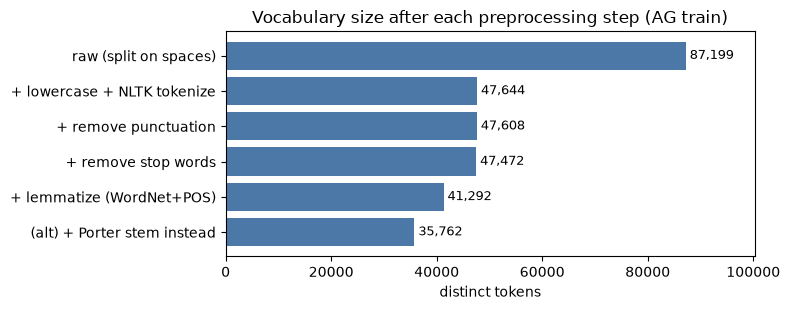

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(vocab.step[::-1], vocab["vocab size"][::-1], color="#4C78A8")
for i, v in enumerate(vocab["vocab size"][::-1]):
    ax.text(v, i, f" {v:,}", va="center", fontsize=9)
ax.set_xlabel("distinct tokens"); ax.set_title("Vocabulary size after each preprocessing step (AG train)")
ax.set_xlim(0, vocab["vocab size"].max() * 1.15)
plt.tight_layout(); plt.show()

In [15]:
save_results("preprocess", {
    "dataset": "ag_train", "n_docs": len(docs), "fast_mode": FAST, "seconds": round(secs, 1),
    "vocab_by_step": dict(zip(vocab.step, vocab["vocab size"].tolist())),
    "tokens_by_step": dict(zip(vocab.step, vocab["tokens"].tolist())),
})

saved results/preprocess.json


PosixPath('/Users/mihirmandavia/nlp-news/results/preprocess.json')

## Viva notes
**Q1. Stemming vs lemmatization?**
Stemming cuts suffixes with fixed rules and can output non-words (*studies* → *studi*). Lemmatization
returns the dictionary form using the POS tag (*was*/VERB → *be*), so it is slower but more accurate.

**Q2. Why keep "not" when removing stop words?**
NLTK's list includes negations, and removing them flips meaning ("not good" → "good"). For
classification and sentiment we keep *no, not, nor, never, n't* (see `src/preprocess.py`).

**Q3. Why does the lemmatizer need POS tags?**
WordNet assumes a noun by default, so *ran* and *better* are left unchanged. Given VERB or ADJ it
returns *run* and *good*. We get POS tags from NLTK's perceptron tagger (`pp.lemmatize`).